#Обучение без учителя.

1. Кластеризация - разделение данных на группы<br>
Сегментирование данных

2. Понижение размерности - из N фичей сделать 2 или 3, и визуализировать<br>
**Для чего может быть полезно понижение размерности:**

*1. Визуализация*

Тяжело визуализировать многомерное пространство

*2. Сжатие с сохранением смысла*

Все признаки важные, отбрасывать их нельзя, но можно их сжать

*3. Абстрактные признаки*

Получить новые признаки на основе старых


**Подключение библиотек и скриптов**

In [ ]:
import numpy as np
import pandas as pd
import pickle

from scipy.spatial.distance import cdist
from mpl_toolkits.mplot3d.axes3d import Axes3D

from sklearn.preprocessing import StandardScaler, RobustScaler

# Кластеризация
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering

from sklearn.neighbors import KNeighborsClassifier

# Понижения размерности
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE


from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score as r2, mean_absolute_error as mae, mean_squared_error as mse

from sklearn.ensemble import GradientBoostingRegressor

import warnings
warnings.filterwarnings('ignore')

import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [ ]:
matplotlib.rcParams.update({'font.size': 12})

In [ ]:
def reduce_dims(df, dims=2, method='pca', perplexity=30):

    assert method in ['pca', 'tsne'], 'Неверно указан метод'

    if method=='pca':
        dim_reducer = PCA(n_components=dims, random_state=42)
        components = dim_reducer.fit_transform(df)
    elif method == 'tsne':
        dim_reducer = TSNE(n_components=dims, learning_rate=250, random_state=42, perplexity=perplexity)
        components = dim_reducer.fit_transform(df)
    else:
        print('Error')

    colnames = ['component_' + str(i) for i in range(1, dims+1)]
    return dim_reducer, pd.DataFrame(data = components, columns = colnames)

In [ ]:
def display_components_in_2D_space(components_df, labels=None):
    components_with_labels_df = pd.concat([components_df, pd.DataFrame(labels)], axis=1)

    figsize = (8, 5)
    if labels is not None:
        components_with_labels_df.plot(kind='scatter', x='component_1', y='component_2',
                                         c=components_with_labels_df.iloc[:, -1], cmap=plt.get_cmap('jet'),
                                         alpha=0.5, figsize=figsize)
    else:
        components_with_labels_df.plot(kind='scatter', x='component_1', y='component_2', alpha=0.5, figsize=figsize)

    plt.xlabel('component_1')
    plt.ylabel('component_2')
    plt.title('2D mapping of objects')
    plt.show()

def display_components_in_3D_space(components_df, labels=None):
    components_with_labels_df = pd.concat([components_df, pd.DataFrame(labels)], axis=1)

    fig = plt.figure(figsize=(7,7))
    ax = fig.add_subplot(111, projection='3d')

    if labels is not None:
        ax.scatter(components_with_labels_df['component_1'],
                   components_with_labels_df['component_2'],
                   components_with_labels_df['component_3'],
                   c=components_with_labels_df.iloc[:, -1],
                   cmap=plt.get_cmap('jet'), alpha=0.5)
    else:
        ax.scatter(components_with_labels_df['component_1'],
                   components_with_labels_df['component_2'],
                   components_with_labels_df['component_3'],
                   alpha=0.5)

    ax.set_xlabel('component_1')
    ax.set_ylabel('component_2')
    ax.set_zlabel('component_3')
    plt.title('3D mapping of objects')
    plt.show()

In [ ]:
def apply_elbow_method(X):
    """Визуализация для метода 'локтя'"""

    distortions = []
    K = range(2,30)
    for k in K:
        kmeanModel = KMeans(n_clusters=k, random_state=33).fit(X)
        distortions.append(sum(np.min(cdist(X, kmeanModel.cluster_centers_, 'euclidean'), axis=1)) / X.shape[0])

    plt.figure(figsize=(8, 5))
    plt.plot(K, distortions, 'bx-')
    plt.xlabel('k')
    plt.ylabel('Distortion')
    plt.title('The Elbow Method showing the optimal k')
    plt.show()

In [ ]:
def display_clusters_distribution(unique_labels, labels_counts):
    """Визуализация распределения классов по кластерам"""
    plt.figure(figsize=(6,4))

    plt.bar(unique, counts)

    plt.xlabel('Clusters')
    plt.xticks(unique)
    plt.ylabel('Count')
    plt.title('Clusters distribution')
    plt.show()

In [ ]:
def evaluate_preds(true_values, pred_values):
    print("R2:\t" + str(round(r2(true_values, pred_values), 3)) + "\n" +
          "MAE:\t" + str(round(mae(true_values, pred_values), 3)) + "\n" +
          "MSE:\t" + str(round(mse(true_values, pred_values), 3)))

    plt.figure(figsize=(10,10))

    sns.scatterplot(x=pred_values, y=true_values)

    plt.xlabel('Predicted values')
    plt.ylabel('True values')
    plt.title('True vs Predicted values')
    plt.show()

Визуализация набора данных MNIST из [статьи](https://habr.com/ru/company/ods/blog/325654/)

In [ ]:
from sklearn import datasets


digits = datasets.load_digits()
X = digits.data
y = digits.target

In [ ]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
X = scaler.fit_transform(X)

In [ ]:
y[:10]

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])

In [ ]:
X.shape

(1797, 64)

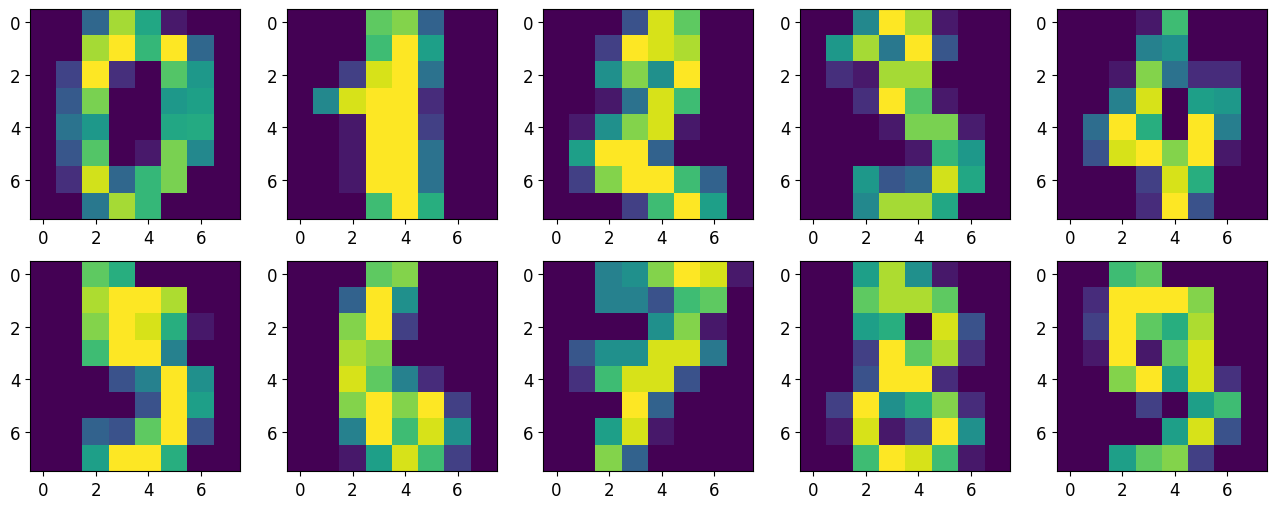

In [ ]:
plt.figure(figsize=(16, 6))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X[i,:].reshape([8,8]))

**PCA**

In [ ]:
pca = PCA(n_components=2)
X_reduced = pca.fit_transform(X)

In [ ]:
dims = 2
colnames = ['component_' + str(i) for i in range(1, dims+1)]
components_X_reduced = pd.DataFrame(data=X_reduced, columns=colnames)
components_X_reduced.head()

display_components_in_2D_space(components_X_reduced, labels=y)

**TSNE**

In [ ]:
%%time

from sklearn.manifold import TSNE
tsne = TSNE(random_state=17, perplexity=25)

X_tsne = tsne.fit_transform(X)

CPU times: user 16.2 s, sys: 122 ms, total: 16.3 s
Wall time: 24.1 s


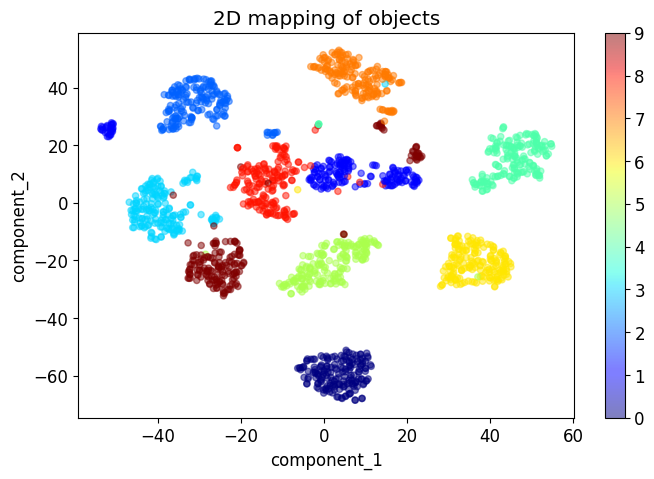

In [ ]:
dims = 2
colnames = ['component_' + str(i) for i in range(1, dims+1)]
components_X_tsne = pd.DataFrame(data=X_tsne, columns=colnames)
components_X_tsne.head()

display_components_in_2D_space(components_X_tsne, labels=y)

**KMeans**

In [ ]:
kmeans = KMeans(n_clusters=10, random_state=42)
labels_clast = kmeans.fit_predict(X)
labels_clast = pd.Series(labels_clast, name='clusters')

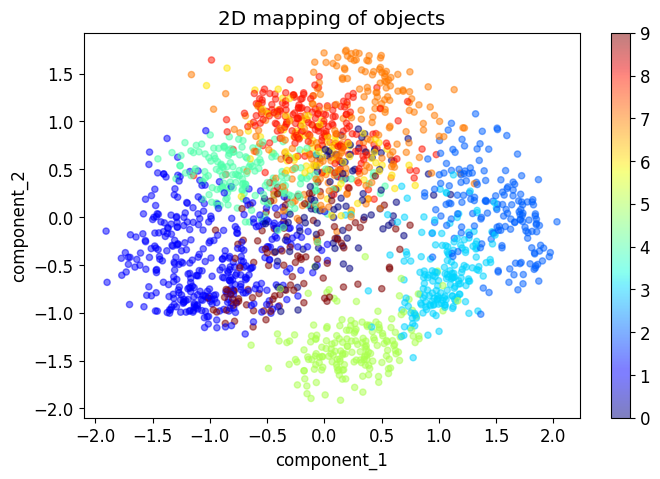

In [ ]:
display_components_in_2D_space(components_X_reduced, labels=labels_clast)

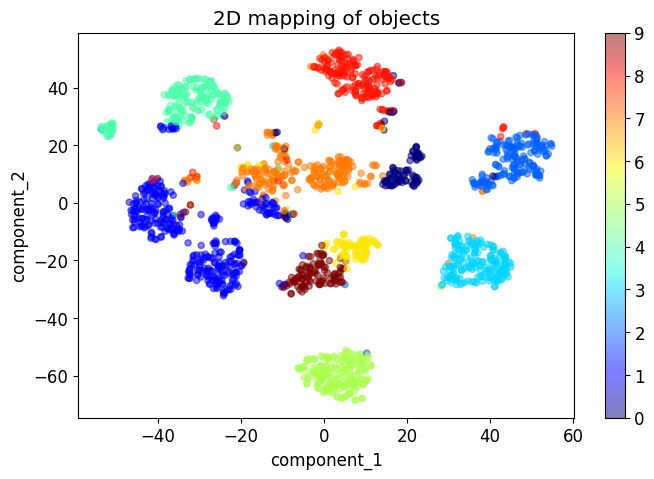

In [ ]:
display_components_in_2D_space(components_X_tsne, labels=labels_clast)

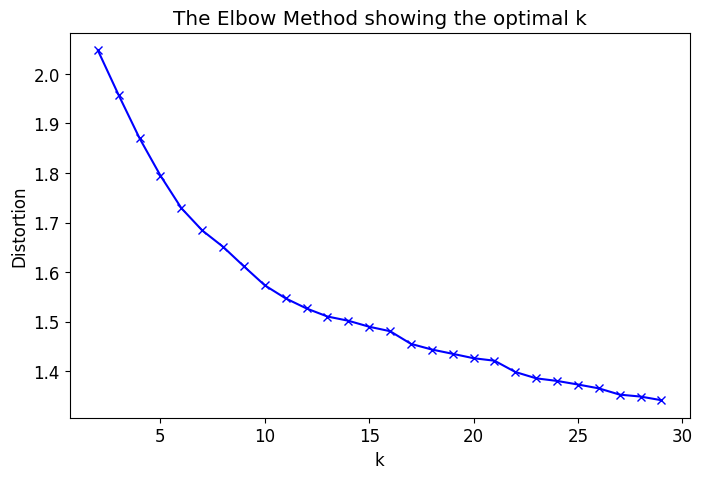

In [ ]:
apply_elbow_method(X)

**DBSCAN**

In [ ]:
dbscan = DBSCAN(eps=1.4, min_samples=5)
labels_clast = dbscan.fit_predict(X)
labels_clast = pd.Series(labels_clast)

unique, counts = np.unique(labels_clast, return_counts=True)
display_clusters_distribution(unique, counts)

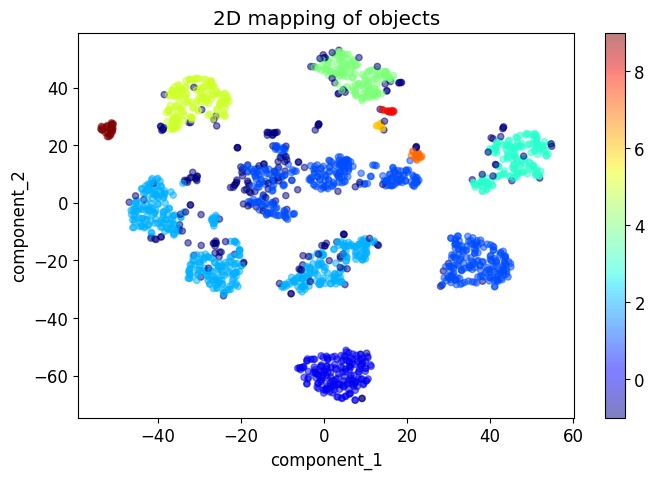

In [ ]:
display_components_in_2D_space(components_X_tsne, labels=labels_clast)

**AgglomerativeClustering**

In [ ]:
# setting distance_threshold=0 ensures we compute the full tree.
model = AgglomerativeClustering(distance_threshold=0, n_clusters=None)

model = model.fit(X)
plt.figure(figsize=(15, 10))
plt.title('Hierarchical Clustering Dendrogram')
# plot the top three levels of the dendrogram

plot_dendrogram(model, truncate_mode='level', p=5)
plt.xlabel("Number of points in node (or index of point if no parenthesis).")
plt.show()

In [ ]:
%%time
aggl = AgglomerativeClustering(n_clusters=10)
labels_clast = aggl.fit_predict(X)
labels_clast = pd.Series(labels_clast)

unique, counts = np.unique(labels_clast, return_counts=True)
display_clusters_distribution(unique, counts)

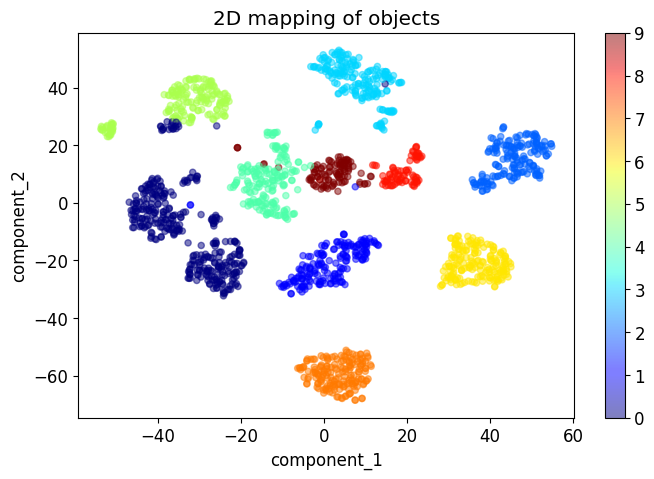

In [ ]:
display_components_in_2D_space(components_X_tsne, labels=labels_clast)

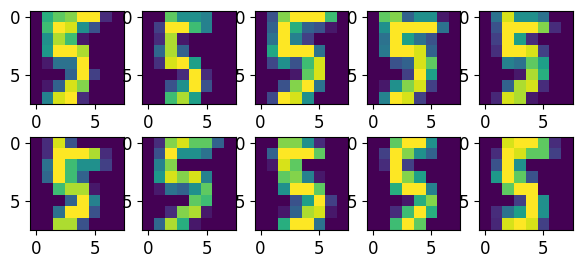

In [ ]:
plt.figure(figsize = (7,3))
for i in range(10):
  plt.subplot(2, 5, i+1)
  plt.imshow(X[labels_clast == 1][i, :].reshape([8,8]))

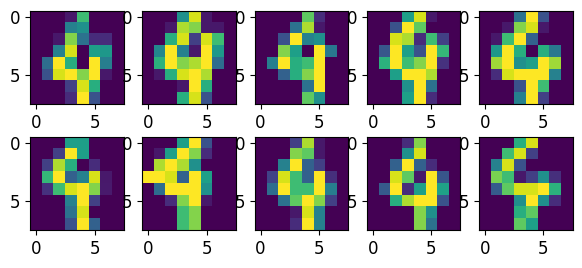

In [ ]:
plt.figure(figsize = (7,3))
for i in range(10):
  plt.subplot(2, 5, i+1)
  plt.imshow(X[labels_clast == 2][i, :].reshape([8,8]))

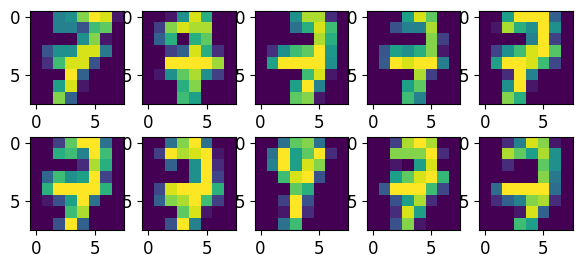

In [ ]:
plt.figure(figsize = (7,3))
for i in range(10):
  plt.subplot(2, 5, i+1)
  plt.imshow(X[labels_clast == 3][i, :].reshape([8,8]))

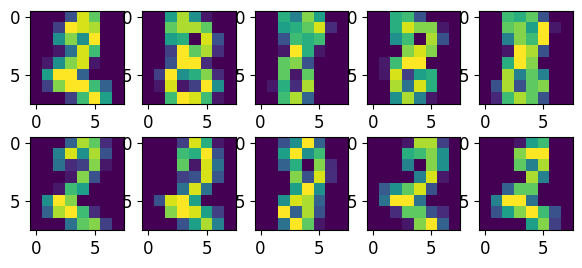

In [ ]:
plt.figure(figsize = (7,3))
for i in range(10):
  plt.subplot(2, 5, i+1)
  plt.imshow(X[labels_clast == 4][i, :].reshape([8,8]))

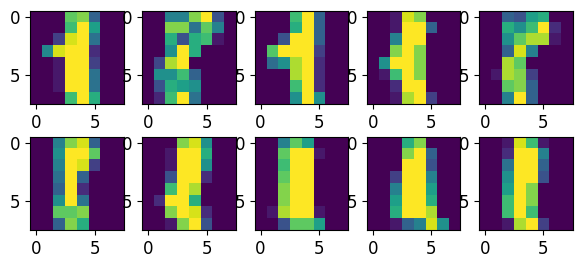

In [ ]:
plt.figure(figsize = (7,3))
for i in range(10):
  plt.subplot(2, 5, i+1)
  plt.imshow(X[labels_clast == 9][i, :].reshape([8,8]))

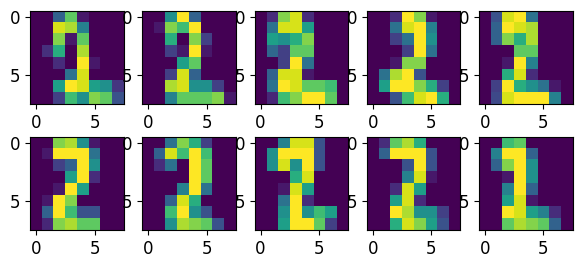

In [ ]:
plt.figure(figsize = (7,3))
for i in range(10):
  plt.subplot(2, 5, i+1)
  plt.imshow(X[labels_clast == 5][i, :].reshape([8,8]))

Новый пример на сгенерированных данных

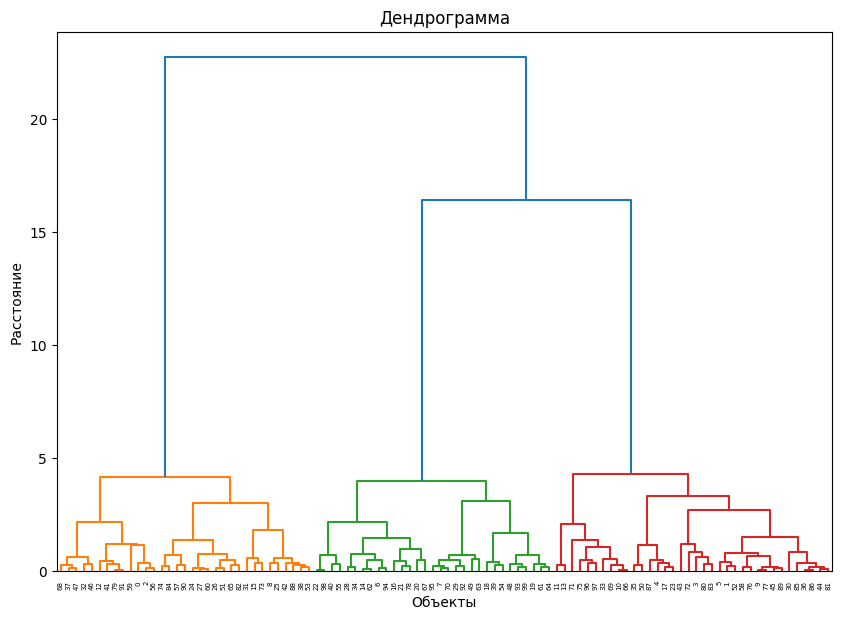

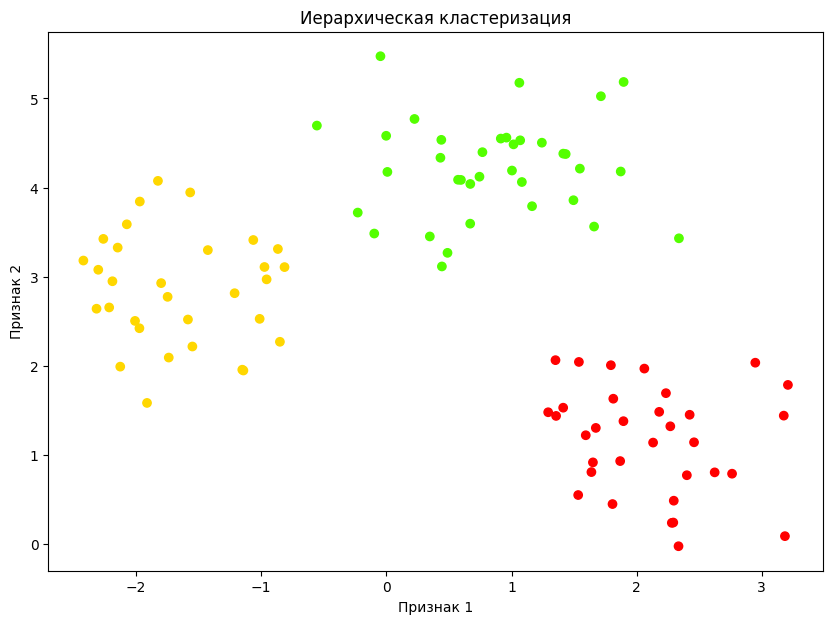

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster

# Генерация случайных данных
X, y = make_blobs(n_samples=100, centers=3, cluster_std=0.60, random_state=0)

# Выполнение иерархической кластеризации
Z = linkage(X, method='ward')

# Построение дендрограммы
plt.figure(figsize=(10, 7))
dendrogram(Z)
plt.title('Дендрограмма')
plt.xlabel('Объекты')
plt.ylabel('Расстояние')
plt.show()

# Определение кластеров на основе заданного порога
threshold = 5  # Задайте порог для определения кластеров
clusters = fcluster(Z, threshold, criterion='distance')

# Визуализация кластеров
plt.figure(figsize=(10, 7))
plt.scatter(X[:, 0], X[:, 1], c=clusters, cmap='prism')
plt.title('Иерархическая кластеризация')
plt.xlabel('Признак 1')
plt.ylabel('Признак 2')
plt.show()

Давайте рассмотрим пример иерархической кластеризации для Wine Dataset. В этом примере мы сначала визуализируем данные с помощью точечного графика, а затем применим иерархическую кластеризацию и построим дендрограмму.

Датасет Wine состоит из 178 образцов вина, описанных 13 химическими признаками. Он включает три класса вин.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import dendrogram, linkage
# Загрузка датасета Wine
wine = load_wine()
X = wine.data
y = wine.target
import pandas as pd
df = pd.DataFrame(data=wine.data, columns=wine.feature_names)
df.head()

In [ ]:
# Загрузка датасета Wine
wine = load_wine()
X = wine.data
y = wine.target

In [ ]:
import pandas as pd
df = pd.DataFrame(data=wine.data, columns=wine.feature_names)
df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


In [ ]:
# Применение PCA для уменьшения размерности до 2D для визуализации
pca = PCA(n_components=2)
X_reduced = pca.fit_transform(X)

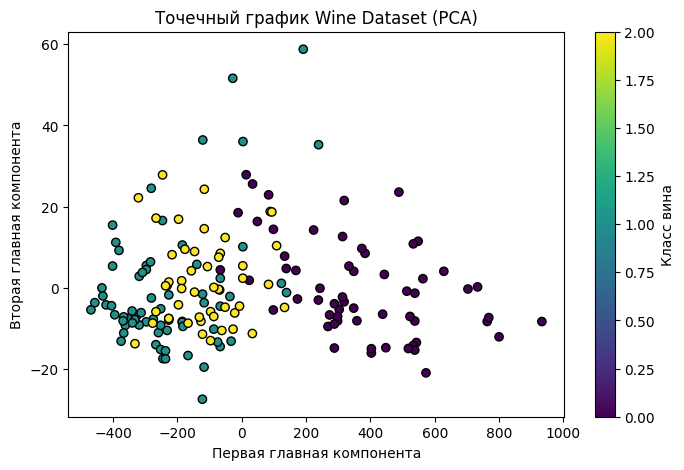

In [ ]:
# Применение PCA для уменьшения размерности до 2D для визуализации
pca = PCA(n_components=2)
X_reduced = pca.fit_transform(X)

# Построение точечного графика
plt.figure(figsize=(8, 5))
plt.scatter(X_reduced[:, 0], X_reduced[:, 1], c=y, cmap='viridis', marker='o', edgecolor='k')
plt.title('Точечный график Wine Dataset (PCA)')
plt.xlabel('Первая главная компонента')
plt.ylabel('Вторая главная компонента')
plt.colorbar(label='Класс вина')
plt.show()

In [ ]:
# Выполнение иерархической кластеризации
Z = linkage(X, method='ward')

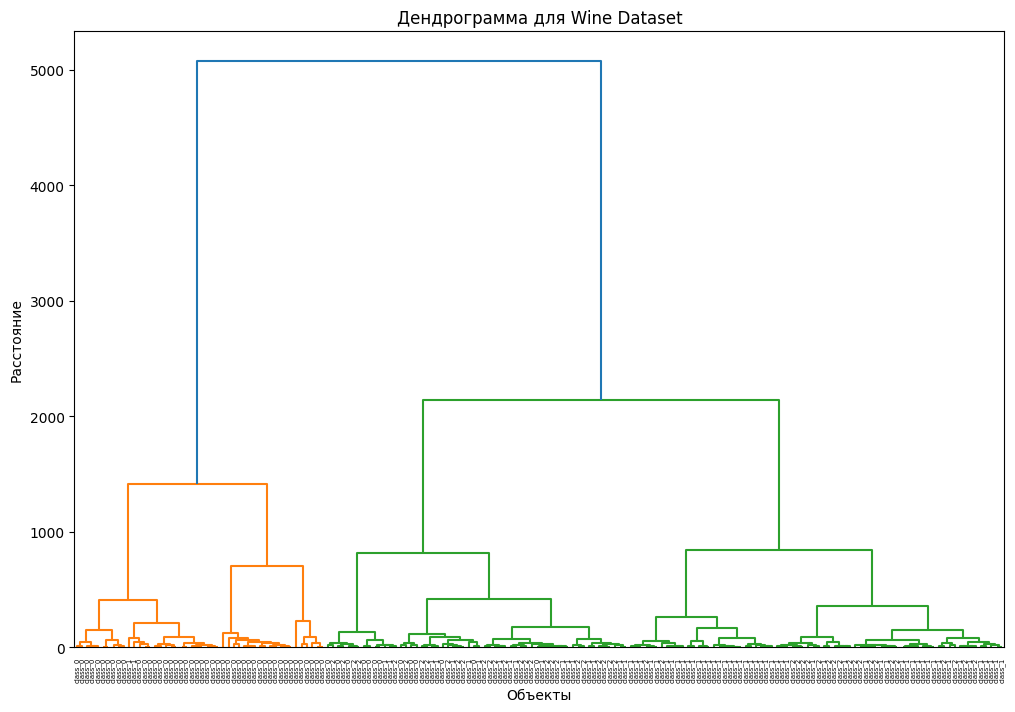

In [ ]:
# Выполнение иерархической кластеризации
Z = linkage(X, method='ward')
# Построение дендрограммы
plt.figure(figsize=(12, 8))
dendrogram(Z, labels=wine.target_names[y])
plt.title('Дендрограмма для Wine Dataset')
plt.xlabel('Объекты')
plt.ylabel('Расстояние')
plt.show()

Количество кластеров: 0
Количество шумов: 178


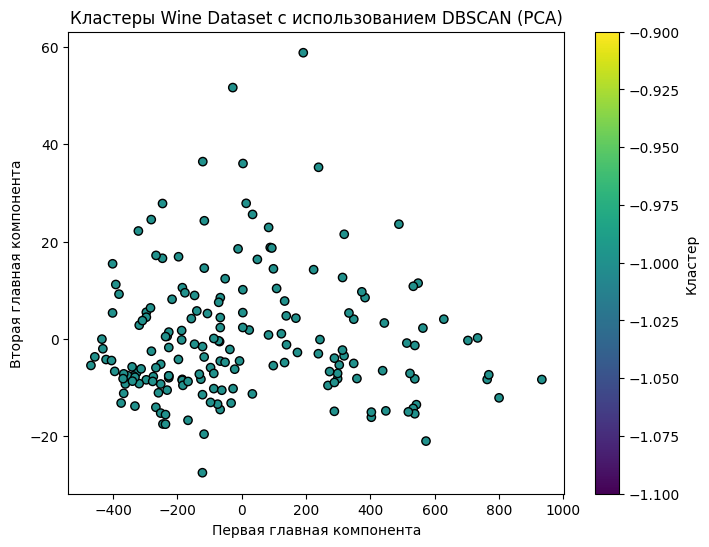

In [ ]:
from sklearn.cluster import DBSCAN

# Применение DBSCAN
dbscan = DBSCAN(eps=0.5, min_samples=5)#3, 2
clusters = dbscan.fit_predict(X)

# Печать количества кластеров и шумов
n_clusters = len(set(clusters)) - (1 if -1 in clusters else 0)
n_noise = list(clusters).count(-1)
print(f'Количество кластеров: {n_clusters}')
print(f'Количество шумов: {n_noise}')

# Визуализация кластеров
plt.figure(figsize=(8, 6))
plt.scatter(X_reduced[:, 0], X_reduced[:, 1], c=clusters, cmap='viridis', marker='o', edgecolor='k')
plt.title('Кластеры Wine Dataset с использованием DBSCAN (PCA)')
plt.xlabel('Первая главная компонента')
plt.ylabel('Вторая главная компонента')
plt.colorbar(label='Кластер')
plt.show()

---
DBSCAN хорошо справляется с данными, содержащими шум или выбросы. Он классифицирует точки, которые не принадлежат ни к одному кластеру, как "шум" (метка -1), что позволяет игнорировать аномальные значения.

Датасеты с высокой плотностью
DBSCAN может быть эффективен для кластеризации данных, где кластеры имеют высокую плотность, а между ними есть области с низкой плотностью. Это делает его идеальным для:

- Данных о местоположении: Например, данные о местоположении пользователей, где плотные группы пользователей могут представлять популярные места.
- Данных о событиях: Например, данные о сейсмических событиях, где кластеры могут представлять зоны повышенной активности.

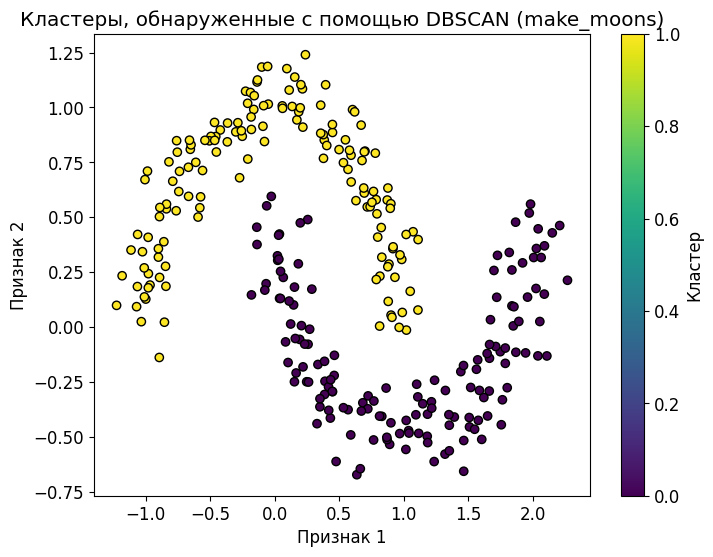

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.cluster import DBSCAN

# Генерация синтетических данных
X, y = make_moons(n_samples=300, noise=0.1, random_state=42)

# Применение DBSCAN
dbscan = DBSCAN(eps=0.2 , min_samples=5)
clusters = dbscan.fit_predict(X)

# Визуализация результатов
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], c=clusters, cmap='viridis', marker='o', edgecolor='k')
plt.title('Кластеры, обнаруженные с помощью DBSCAN (make_moons)')
plt.xlabel('Признак 1')
plt.ylabel('Признак 2')
plt.colorbar(label='Кластер')
plt.show()